# Loop Slot: HFSS Plots and S11 Verification

Read the two `loop_slot` CSV files from this folder. Compare the exported S11 with

$$ 
Z_\mathrm{in}=\operatorname{Re}(Z_{11})+j\operatorname{Im}(Z_{11}),\qquad
\Gamma=\frac{Z_\mathrm{in}-Z_0}{Z_\mathrm{in}+Z_0},\qquad
S_{11,\mathrm{dB}}=20\log_{10}|\Gamma| 
$$

Use a real reference impedance of **50 ohms**, editable below. The S11 CSV contains only dB magnitude, so this comparison cannot verify phase or establish how HFSS internally computed the results. Select **Run All** to refresh.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from plotting_hfss import PLOT_CONFIG, plot_hfss_curves

%matplotlib inline

f_s, s11_db = np.loadtxt("loop_slot_S_Parameter_Plot_1.csv", delimiter=",", skiprows=1, unpack=True)
f_z, re_z, im_z = np.loadtxt("loop_slot_Z_Parameter_Plot_1.csv", delimiter=",", skiprows=1, unpack=True)
assert np.array_equal(f_s, f_z), "Frequency grids must match for pointwise comparison."
assert np.isfinite([s11_db, re_z, im_z]).all(), "Data contain non-finite values."

z0 = 50.0  # Reference impedance in ohms
z_in = re_z + 1j * im_z
s11_from_z = (z_in - z0) / (z_in + z0)
s11_calc_db = 20 * np.log10(np.abs(s11_from_z))
error_db = s11_calc_db - s11_db

print(f"Frequency: {f_s[0]:g} to {f_s[-1]:g} GHz ({len(f_s)} points)")
print(f"Minimum Re(Z): {re_z.min():.6f} ohms")
print(f"Maximum absolute error: {np.max(np.abs(error_db)):.3e} dB")
print(f"RMS error: {np.sqrt(np.mean(error_db**2)):.3e} dB")
print(f"Magnitude matches within 1e-9 dB: {np.allclose(s11_calc_db, s11_db, rtol=0, atol=1e-9)}")

Frequency: 2 to 5 GHz (301 points)
Minimum Re(Z): 4.445804 ohms
Maximum absolute error: 2.487e-14 dB
RMS error: 7.559e-15 dB
Magnitude matches within 1e-9 dB: True


In [5]:
# normalize frequency
lambda0 = 100 # mm
freq0 = 3e8 / (lambda0 * 1e-3) / 1e9  # GHz
f_z_norm = f_z / freq0

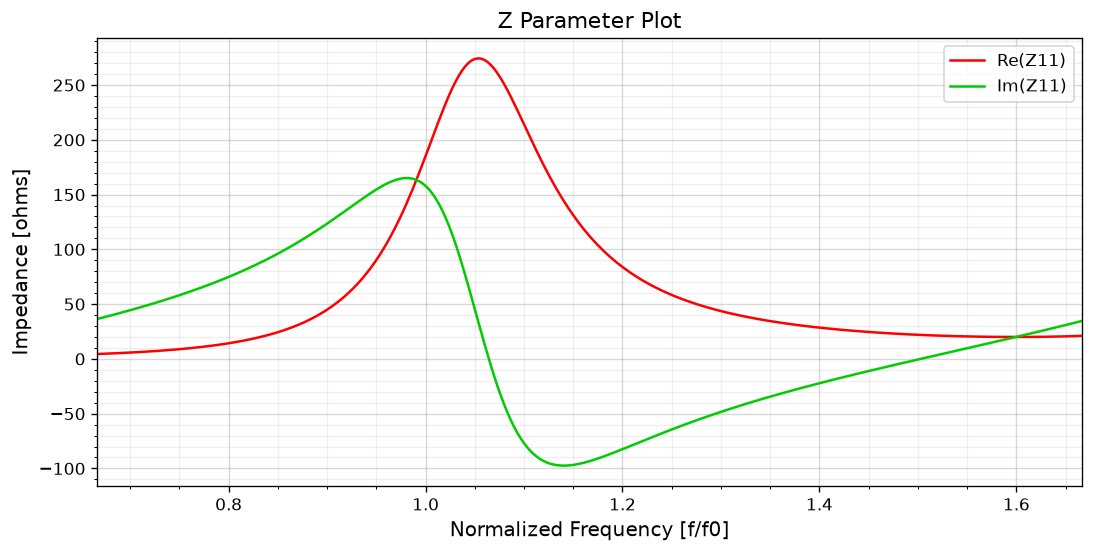

In [7]:
fig_z, az = plot_hfss_curves(
    f_z_norm, [re_z, im_z], labels=["Re(Z11)", "Im(Z11)"],
    colors=["red", "#00cc00"], title="Z Parameter Plot",
    xlabel="Normalized Frequency [f/f0]",
    ylabel="Impedance [ohms]",
)

### Verify the $S_{11}$ calculation
$$
S_{11} = \frac{Z_{\text{in}} - Z_0}{Z_{\text{in}} + Z_0}
$$
I used $Z_0=50\ \Omega$ in this HFSS simulation.

- The exported data agree with the $Z_0=50\ \Omega$ impedance formula to floating-point precision (maximum error approximately **2.49e-14 dB**). This verifies the magnitude relation for this dataset. Re(Z) is positive throughout the supplied 2-5 GHz range.
- from this we can see that the impedence $Z_{in}$ and $S_{11}$ for a fixed $Z_0$ is equivalent. But if we don't know the intrinsic impedence of the design, we may get a $S_{11}$ that has a dip in a frequency different from the resonant frequency. So it is better to look at the $\Re Z$ and $\Im Z$, if $\Im Z$ cross zero from positive to negative, then the corresponsing frequency may be the resonant frequency.

In [8]:
f_s_norm = f_s / freq0

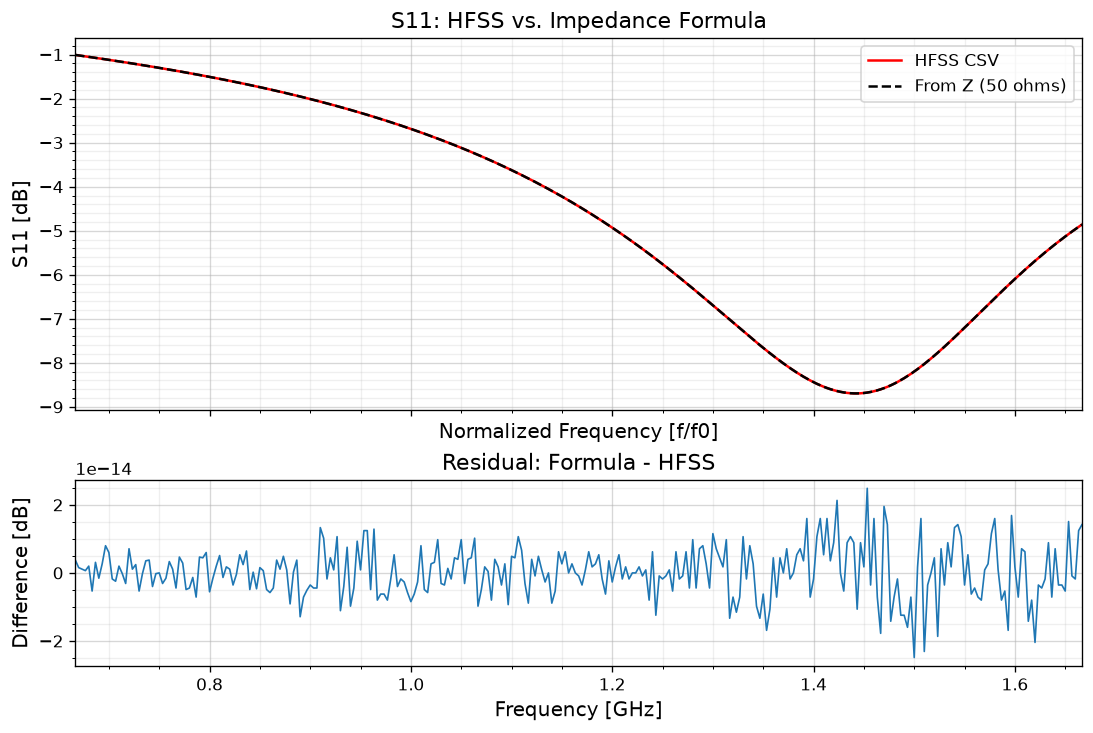

In [9]:
with plt.rc_context(PLOT_CONFIG):
    fig_s, (a_s, a_err) = plt.subplots(
        2, 1, figsize=(9, 6), sharex=True, height_ratios=[2, 1],
        layout="constrained",
    )

plot_hfss_curves(
    f_s_norm, [s11_db, s11_calc_db], ax=a_s,
    labels=["HFSS CSV", f"From Z ({z0:g} ohms)"],
    colors=["red", "black"], linestyles=["-", "--"],
    title="S11: HFSS vs. Impedance Formula", xlabel="Normalized Frequency [f/f0]", ylabel="S11 [dB]",
    flag_show=False,
)
plot_hfss_curves(
    f_s_norm, error_db, ax=a_err, title="Residual: Formula - HFSS",
    ylabel="Difference [dB]", linewidth=1, flag_show=False,
)
a_err.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
plt.show()